# Supermarket Sales Analysis
Cleaned and extended version of *Sales Visualization*. Covers data repair, branch/product performance, **trends**, **customer segments** and **ratings**.

**Data notes (found while tidying)**
- `Date` mixed text (`M/D/YYYY`) with Excel dates whose day and month had been swapped. Fixed below; the repaired range is 1 Jan to 30 Mar 2019 (89 distinct days).
- `Revenue` (Unit price x Quantity) is identical to `cogs`, and `Sales` = Revenue x 1.05 (5% tax). We use **Sales** as the headline figure; `gross income` is just the tax.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({'figure.figsize':(8,4.5),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.3,'axes.axisbelow':True})
COLORS=['#2a6f97','#e07a5f','#81b29a','#f2cc8f','#6d597a','#b56576']
DATA='SuperMarket_Analysis.xlsx'   # put the file next to this notebook

## 1. Load and clean

In [2]:
df = pd.read_excel(DATA)

def fix_date(v):
    if isinstance(v, str):                       # '1/27/2019' -> already M/D/YYYY
        return pd.to_datetime(v, format='%m/%d/%Y')
    return pd.Timestamp(year=v.year, month=v.day, day=v.month)   # Excel swapped D/M

df['Date'] = df['Date'].map(fix_date)
df['Hour'] = pd.to_datetime(df['Time'].astype(str)).dt.hour
df['Month'] = df['Date'].dt.to_period('M').astype(str)
df['Weekday'] = df['Date'].dt.day_name()
df['Branch (City)'] = df['Branch'] + ' (' + df['City'] + ')'

# sanity checks
assert df['Invoice ID'].is_unique and df.isna().sum().sum() == 0
assert np.allclose(df['Sales'], df['Unit price']*df['Quantity']*1.05)
print(df['Date'].min().date(), '->', df['Date'].max().date(), '|', df['Date'].nunique(), 'days |', len(df), 'invoices')
df.head()

2019-01-01 -> 2019-03-30 | 89 days | 1000 invoices


/tmp/ipykernel_225/2692397006.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Hour'] = pd.to_datetime(df['Time'].astype(str)).dt.hour


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,...,Time,Payment,cogs,gross margin percentage,gross income,Rating,Hour,Month,Weekday,Branch (City)
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,...,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1,13,2019-01,Saturday,Alex (Yangon)
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,...,10:29:00,Cash,76.40,4.761905,3.8200,9.6,10,2019-03,Friday,Giza (Naypyitaw)
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,...,13:23:00,Credit card,324.31,4.761905,16.2155,7.4,13,2019-03,Sunday,Alex (Yangon)
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,...,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4,20,2019-01,Sunday,Alex (Yangon)
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,...,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3,10,2019-02,Friday,Alex (Yangon)


In [3]:
def bar(series, title, ylabel='Sales', horizontal=False, fmt='{:,.0f}'):
    fig, ax = plt.subplots()
    s = series.sort_values(ascending=horizontal)
    b = (ax.barh if horizontal else ax.bar)(s.index, s.values, color=COLORS[0])
    ax.bar_label(b, labels=[fmt.format(v) for v in s.values], padding=3)
    ax.set_title(title, fontweight='bold'); (ax.set_xlabel if horizontal else ax.set_ylabel)(ylabel)
    ax.grid(axis='x' if not horizontal else 'y', visible=False)
    plt.xticks(rotation=0 if horizontal else 25, ha='center' if horizontal else 'right'); plt.tight_layout(); plt.show()

total = df['Sales'].sum()
print(f"Total sales {total:,.0f} | avg invoice {df['Sales'].mean():,.1f} | avg rating {df['Rating'].mean():.2f}")

Total sales 322,967 | avg invoice 323.0 | avg rating 6.97


## 2. Where the money is: branch and product line

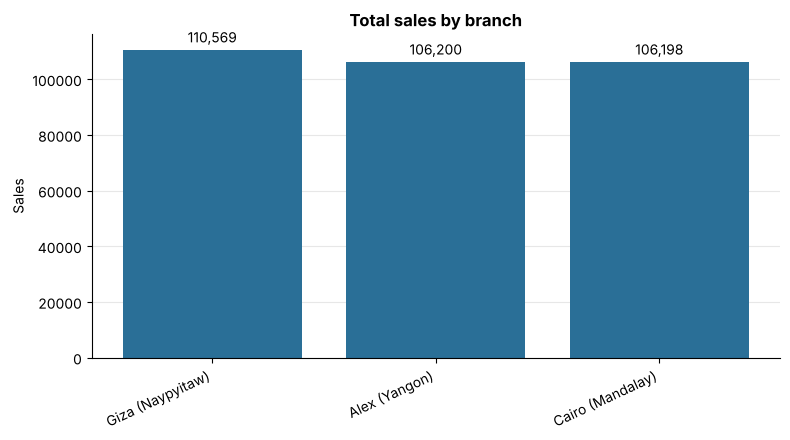

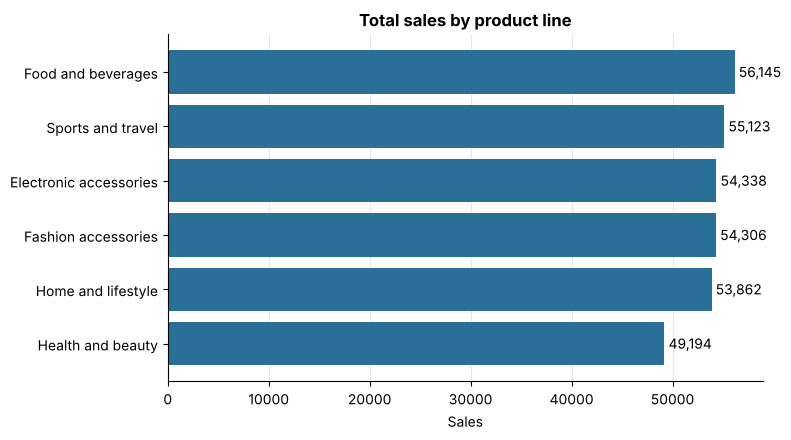

Branch,Alex,Cairo,Giza
Product line,,,
Electronic accessories,18317.000000,17051.000000,18969.000000
Fashion accessories,16333.000000,16413.000000,21560.000000
Food and beverages,17163.000000,15215.000000,23767.000000
Health and beauty,12598.000000,19981.000000,16615.000000
Home and lifestyle,22417.000000,17549.000000,13896.000000
Sports and travel,19373.000000,19988.000000,15762.000000


In [4]:
bar(df.groupby('Branch (City)')['Sales'].sum(), 'Total sales by branch')
bar(df.groupby('Product line')['Sales'].sum(), 'Total sales by product line', horizontal=True)
df.pivot_table(index='Product line', columns='Branch', values='Sales', aggfunc='sum').round(0).style.background_gradient(axis=None, cmap='Blues')

Branches are within ~4% of each other and product lines within ~14%. The significance tests below show these gaps are well within what chance produces.

In [5]:
def kw(col, by): 
    return stats.kruskal(*[g[col].values for _, g in df.groupby(by)]).pvalue
print('Sales differ by branch?        p =', round(kw('Sales','Branch'),3))
print('Sales differ by product line?  p =', round(kw('Sales','Product line'),3))

Sales differ by branch?        p = 0.812
Sales differ by product line?  p = 0.827


## 3. Trends over time

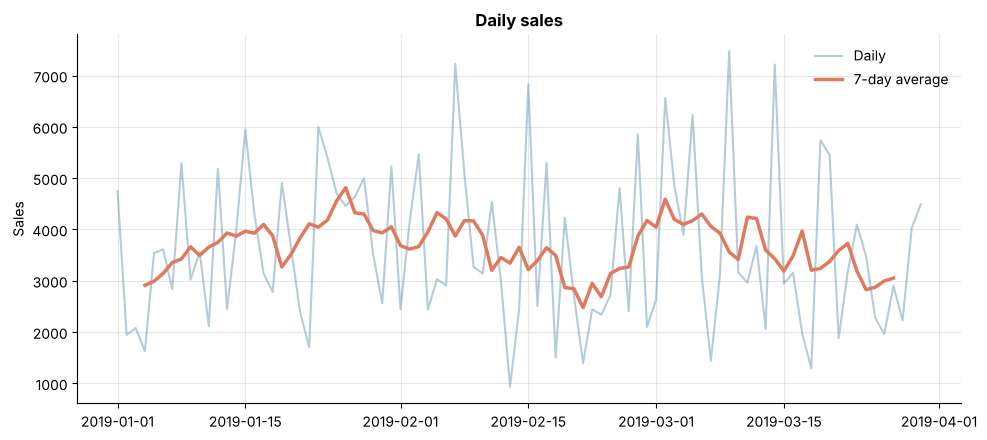

,Sales,Invoices,Avg_invoice
Month,,,
2019-01,116291.9,352,330.4
2019-02,97219.4,303,320.9
2019-03,109455.5,345,317.3


In [6]:
daily = df.groupby('Date')['Sales'].sum()
fig, ax = plt.subplots(figsize=(10,4.5))
ax.plot(daily.index, daily.values, color=COLORS[0], alpha=.35, label='Daily')
ax.plot(daily.rolling(7, center=True).mean(), color=COLORS[1], lw=2.5, label='7-day average')
ax.set_title('Daily sales', fontweight='bold'); ax.set_ylabel('Sales'); ax.legend(frameon=False); plt.tight_layout(); plt.show()

m = df.groupby('Month').agg(Sales=('Sales','sum'), Invoices=('Sales','size'), Avg_invoice=('Sales','mean')).round(1)
m

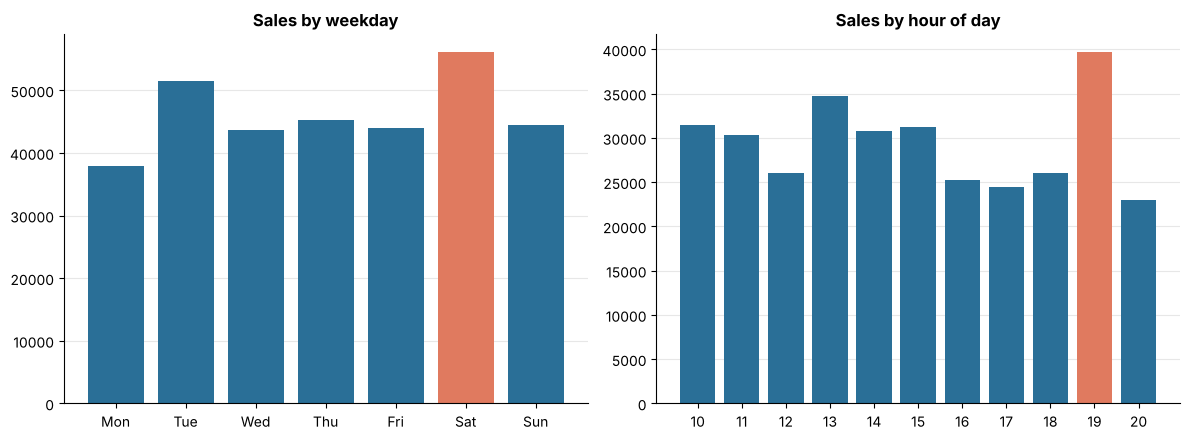

In [7]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
wd = df.groupby('Weekday')['Sales'].sum().reindex(order)
hr = df.groupby('Hour')['Sales'].sum()
fig, axs = plt.subplots(1, 2, figsize=(12,4.5))
axs[0].bar(wd.index.str[:3], wd.values, color=[COLORS[1] if v==wd.max() else COLORS[0] for v in wd]); axs[0].set_title('Sales by weekday', fontweight='bold')
axs[1].bar(hr.index, hr.values, color=[COLORS[1] if v==hr.max() else COLORS[0] for v in hr]); axs[1].set_title('Sales by hour of day', fontweight='bold'); axs[1].set_xticks(hr.index)
for a in axs: a.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

- **February was the weak month** (fewer days, 303 invoices vs ~350 in Jan/Mar), but average invoice value was steady.
- **Saturday** is the best weekday and **Monday** the weakest; **7 pm** is the peak hour, with a second bump around 1 pm. Late afternoon (4-5 pm) and 8 pm are the quietest.
- These are totals, so weekday counts include small differences in how many of each weekday fall in the 13-week window.

## 4. Customer segments

In [8]:
seg = lambda c: df.groupby(c).agg(Invoices=('Sales','size'), Sales=('Sales','sum'), Avg_invoice=('Sales','mean'),
                                  Avg_qty=('Quantity','mean'), Avg_rating=('Rating','mean')).round(2)
for c in ['Customer type','Gender','Payment']:
    display(seg(c))

,Invoices,Sales,Avg_invoice,Avg_qty,Avg_rating
Customer type,,,,,
Member,565,189694.76,335.74,5.63,6.92
Normal,435,133271.98,306.37,5.35,7.04


,Invoices,Sales,Avg_invoice,Avg_qty,Avg_rating
Gender,,,,,
Female,571,194671.84,340.93,5.76,6.96
Male,429,128294.91,299.06,5.18,6.99


,Invoices,Sales,Avg_invoice,Avg_qty,Avg_rating
Payment,,,,,
Cash,344,112206.57,326.18,5.51,6.97
Credit card,311,100767.07,324.01,5.54,7.00
Ewallet,345,109993.11,318.82,5.48,6.95


Female vs Male invoice value:   p = 0.0075
Member vs Normal invoice value: p = 0.0812


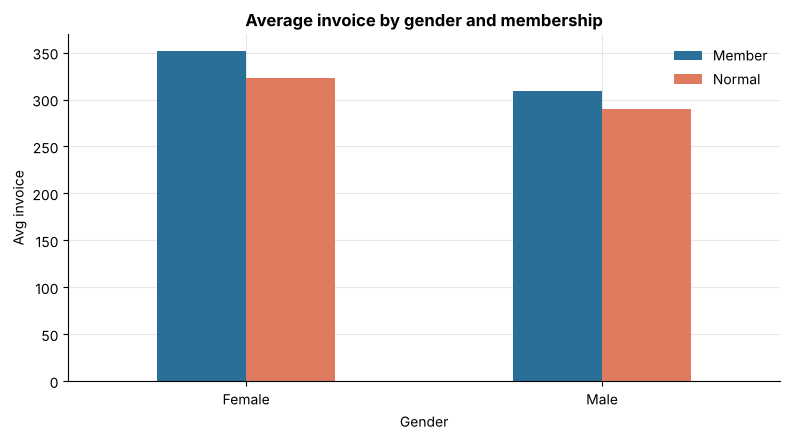

Product line,Electronic accessories,Fashion accessories,Food and beverages,Health and beauty,Home and lifestyle,Sports and travel
Gender,,,,,,
Female,31227.000000,33920.000000,36466.000000,23419.000000,33721.000000,35920.000000
Male,23111.000000,20386.000000,19679.000000,25775.000000,20141.000000,19202.000000


In [9]:
f, m_ = df.loc[df.Gender=='Female','Sales'], df.loc[df.Gender=='Male','Sales']
mem, nor = df.loc[df['Customer type']=='Member','Sales'], df.loc[df['Customer type']=='Normal','Sales']
print('Female vs Male invoice value:   p =', round(stats.mannwhitneyu(f, m_).pvalue,4))
print('Member vs Normal invoice value: p =', round(stats.mannwhitneyu(mem, nor).pvalue,4))

fig, ax = plt.subplots()
g = df.groupby(['Gender','Customer type'])['Sales'].mean().unstack()
g.plot.bar(ax=ax, color=COLORS[:2], rot=0); ax.set_title('Average invoice by gender and membership', fontweight='bold'); ax.set_ylabel('Avg invoice'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

df.pivot_table(index='Gender', columns='Product line', values='Sales', aggfunc='sum').round(0).style.background_gradient(axis=1, cmap='Blues')

- **Women spend more per invoice** (about 341 vs 299) and account for 57% of invoices. This is the one statistically solid difference in the data (p < 0.01).
- **Members** make 56.5% of invoices and spend about 10% more per invoice, but that gap is *not* significant at the 5% level (p ~ 0.08), so treat it as a lead, not a finding.
- Payment method makes no real difference to spend or rating.

## 5. Ratings

count    1000.00
mean        6.97
std         1.72
min         4.00
25%         5.50
50%         7.00
75%         8.50
max        10.00
Name: Rating, dtype: float64


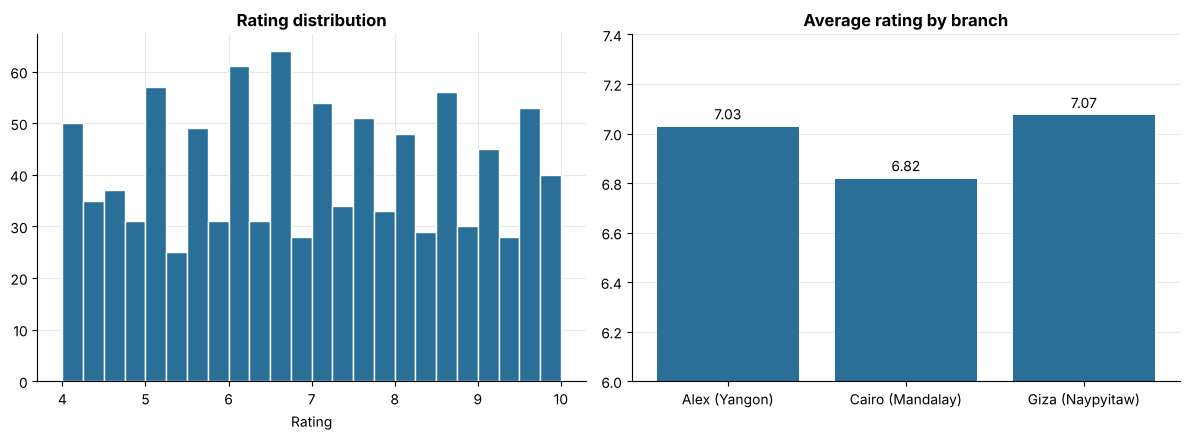

Rating differs by branch?        p = 0.13
Rating differs by product line?  p = 0.742
Rating vs Sales (Spearman)       rho = -0.017, p = 0.586


In [10]:
print(df['Rating'].describe().round(2))
fig, axs = plt.subplots(1, 2, figsize=(12,4.5))
axs[0].hist(df['Rating'], bins=24, color=COLORS[0], edgecolor='white'); axs[0].set_title('Rating distribution', fontweight='bold'); axs[0].set_xlabel('Rating')
r = df.groupby('Branch (City)')['Rating'].mean(); axs[1].bar(r.index, r.values, color=COLORS[0]); axs[1].set_ylim(6, 7.4)
axs[1].bar_label(axs[1].containers[0], fmt='%.2f', padding=3); axs[1].set_title('Average rating by branch', fontweight='bold'); axs[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

print('Rating differs by branch?        p =', round(kw('Rating','Branch'),3))
print('Rating differs by product line?  p =', round(kw('Rating','Product line'),3))
print('Rating vs Sales (Spearman)       rho = %.3f, p = %.3f' % stats.spearmanr(df['Rating'], df['Sales']))

Ratings run from 4 to 10 with a mean of 6.97 and are spread almost evenly across that range. Cairo is lowest (6.82) but the branch difference is not significant (p ~ 0.13), and rating is unrelated to basket size, product line, customer type or payment method.

Because nothing explains the ratings, the data may not capture what drives satisfaction (wait time, staff, stock). It is worth collecting before drawing conclusions.

## 6. Summary
| Question | Answer |
|---|---|
| Best branch / product | Giza and Food and beverages lead, but only by small margins that are within chance |
| Trend | Flat-to-seasonal: Jan 116k, Feb 97k, Mar 109k; Saturday and 7 pm are peaks |
| Who spends more | Women (significant); Members (suggestive only) |
| Ratings | Average 7.0, no significant drivers |

**Caveat:** the figures are almost perfectly uniform and show no structure beyond gender, which is typical of simulated sample data. Treat the "no difference" results as real for this dataset but be cautious about generalising.